# 17 - Visualization Masterclass

**Part B - Petrophys Curriculum**

`petrophys.visualization` is a full plotting suite, not a single `plot()` call. This
notebook is the **gallery**: we render every major figure type on real wells and briefly
explain what each is for and when to reach for it. Treat it as a visual index you can
return to when you need the right plot for a task.

## Learning goals

- Drive the **XML-template log viewer** (`create_log_viewer`) with named templates,
  the `auto`/adaptive template, and `DEFAULT_LOG_VIEWER_TEMPLATES`.
- Render the **triple combo** (`create_triple_combo`) - the standard first-look display.
- Work through the **crossplot family**: `create_nd_crossplot`, `create_pickett_plot`,
  `create_mn_plot`, `create_mid_plot`, `create_buckles_plot`, `create_hingle_plot`.
- Use the **specialist panels**: `create_flow_unit_plot` on real 30/6-5 core
  plugs and `create_nmr_panel` on the bundled real Daydream 1 CMR; know what
  `create_fmi_panel` needs (notebook 16 renders it on the real Daydream FMI).
- Overlay **zone flags** and **formation shading** (`plot_zone_flags`, `add_zone_shading`).

## Why this matters

Petrophysical interpretation is a visual discipline. The same numbers tell different
stories depending on the axes you put them on: a Pickett plot exposes the water line and
cementation exponent; an N-D crossplot separates lithology and gas; a Buckles plot tests
whether a zone is at irreducible water. Knowing which figure answers which question - and
letting the library build it from a template - is most of the craft.

### Prerequisites

Assumes the Part A workflow notebooks (you should recognise `PHIE`, `SW`, `PERM`, and the
`NET_ROCK/NET_RES/NET_PAY` flags). We run the standard workflow once up front so every
well carries a full interpreted curve set for the plots to draw.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las
from petrophys.workflow import BatchProcessor
from petrophys import visualization as V
from petrophys.visualization import (
    create_log_viewer, DEFAULT_LOG_VIEWER_TEMPLATES,
    create_adaptive_log_viewer_template,
    create_triple_combo,
    create_nd_crossplot, create_pickett_plot,
    create_mn_plot, create_mid_plot,
    create_buckles_plot, create_hingle_plot,
    create_nmr_panel, create_fmi_panel, create_flow_unit_plot,
    plot_zone_flags, add_zone_shading,
)
from petrophys.visualization.specialist_panels import has_nmr_curves
from petrophys.evaluation import calculate_flow_units

print("petrophys", petrophys.__version__)
print("named templates:", list(DEFAULT_LOG_VIEWER_TEMPLATES.keys()))

petrophys 0.1.0
named templates: ['raw', 'triple_combo', 'comprehensive', 'full', 'petrophysics', 'interpretation', 'minerals', 'geolink', 'geolink_full', 'standard', 'universal']


### Load and interpret the teaching wells

We use two contrasting wells:

- **30/6-5** - a North Sea **clastic** well with a rich curve set and a vendor
  `LITHOLOGY_GEOLINK` log (depth in metres).
- **HW-3** - a **carbonate** well from the Costa field (depth in feet).

Running `BatchProcessor` with its default standard workflow adds `VCL`, `PHIE`, `SW`,
`PERM`, and net-pay flags to each.

In [2]:
bp = BatchProcessor()

geo = read_las(petrophys.sample("30_6-5"))
geo = bp.process_wells([geo])[0].result.well

carb = read_las(petrophys.sample("HW-3"))
carb = bp.process_wells([carb])[0].result.well

def sanitize(s):
    return str(s).encode("ascii", "replace").decode("ascii")

print("30/6-5 :", geo.n_samples, "samples,", geo.depth_unit,
      "| field:", sanitize(geo.header.field))
print("HW-3   :", carb.n_samples, "samples,", carb.depth_unit)
print("30/6-5 interpreted curves present:",
      [c for c in ("VCL", "PHIE", "SW", "PERM", "NET_PAY") if geo.has_curve(c)])

# Reusable working intervals on 30/6-5:
GEO_FULL = (2600.0, 3200.0)     # broad reservoir section
GEO_LITH = (2784.0, 3176.0)     # PEF live here -> lithology crossplots
GEO_WATER = (3223.0, 3556.0)    # Statfjord water-bearing sand -> Pickett/Hingle

30/6-5 : 22176 samples, m | field: OSEBERG ??ST
HW-3   : 431 samples, ft
30/6-5 interpreted curves present: ['VCL', 'PHIE', 'SW', 'PERM', 'NET_PAY']


## 1. Template log viewer

`create_log_viewer` builds a multi-track figure from a PetroPy-style **XML template**.
You can pass a named built-in template via `template_defaults=...` or let it choose one
automatically with `"auto"`. The available names are the keys of
`DEFAULT_LOG_VIEWER_TEMPLATES` (several are aliases pointing at the same XML).

The factory renders **eagerly**: pass `depth_range=` (and any styling) to
`create_log_viewer` itself, and the returned `LogViewer` already holds the finished,
windowed figure as `viewer.fig` / `viewer.axes`. Do **not** call `.create()` on it
again - that re-renders from scratch and, called bare, falls back to the full well.
Use `.save(path)` to export and `.close()` to free memory in loops; unrecognised or
dropped curves are recorded in `viewer.warnings`.

geolink_full template -> 9 tracks
viewer.warnings: 16
  - Curve 'RXO' not available for log viewer template
  - Curve 'NPHI_HC' not available for log viewer template
  - Curve 'PHIT_GAS_CORR' not available for log viewer template
  - Curve 'SW_ARCHIE' not available for log viewer template
  - Curve 'SW_INDONESIAN' not available for log viewer template
  - Curve 'SW_SIMANDOUX' not available for log viewer template
  - Curve 'BVW' not available for log viewer template
  - Curve 'MHI' not available for log viewer template
  - Curve 'PERM_TIMUR' not available for log viewer template
  - Curve 'PERM_COATES' not available for log viewer template
  - Curve 'PERM_MORRIS_BIGGS_MODIFIED' not available for log viewer template
  - Curve 'VQUAR' not available for log viewer template
  - Curve 'VCALC' not available for log viewer template
  - Curve 'VDOLO' not available for log viewer template
  - Curve 'VANHY' not available for log viewer template
  - Curve 'SEALFLAG' not available for log viewer t

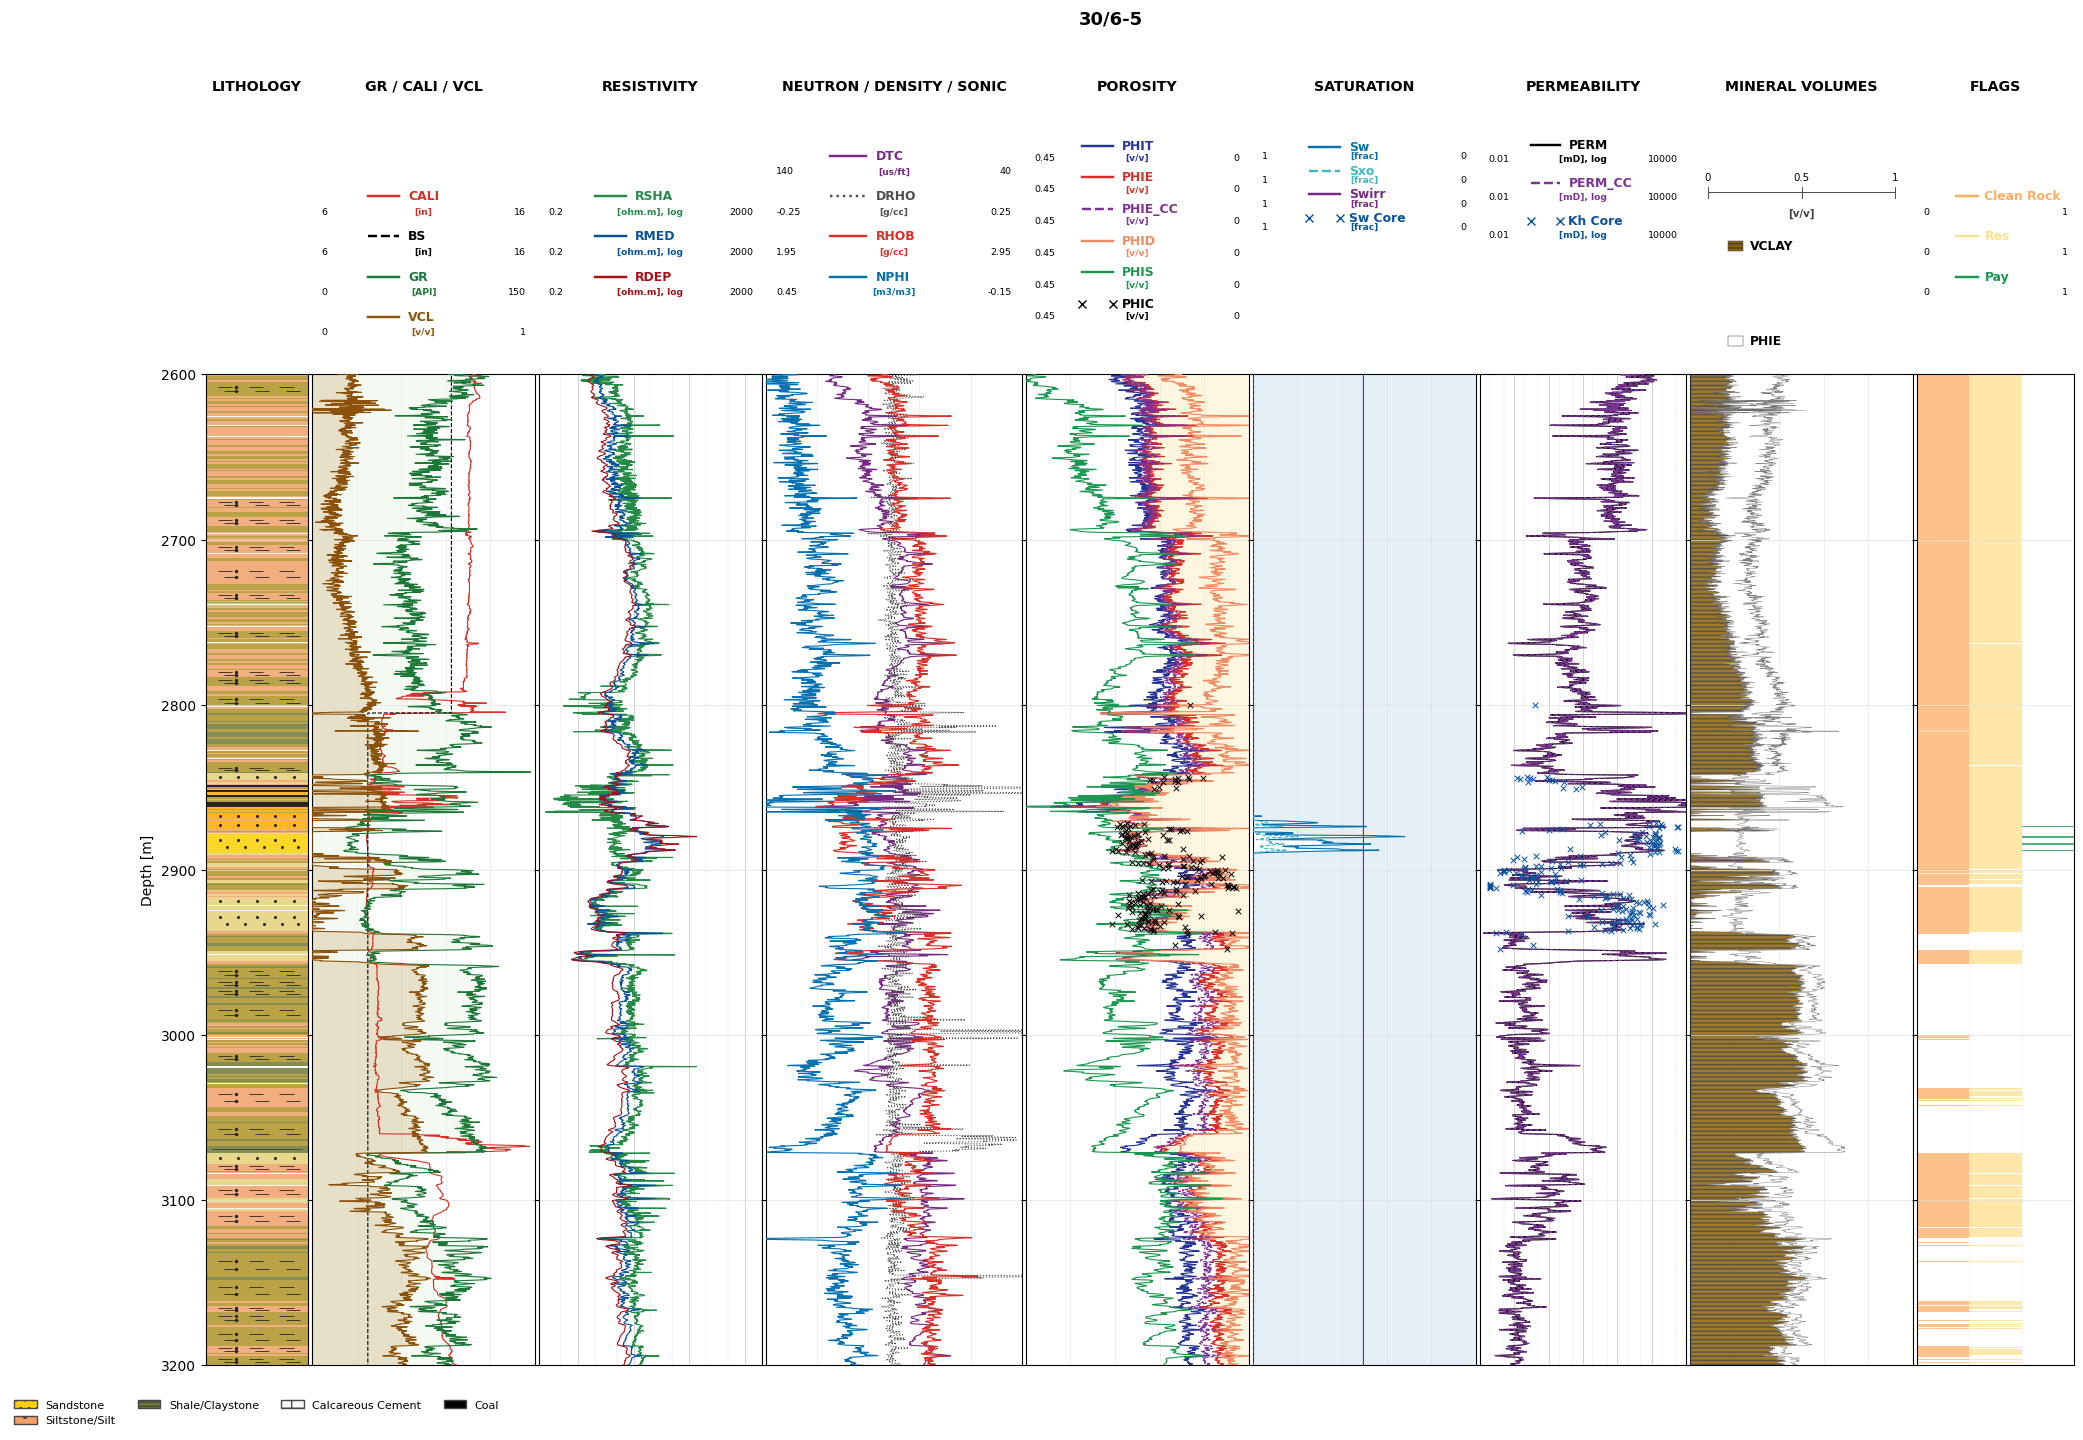

In [3]:
viewer = create_log_viewer(geo, template_defaults="geolink_full", depth_range=GEO_FULL)
print("geolink_full template ->", len(viewer.axes), "tracks")
print("viewer.warnings:", len(viewer.warnings))
for w in viewer.warnings:
    print("  -", w)

### The adaptive `auto` template

`template_defaults="auto"` inspects the curves actually present and assembles tracks on
the fly (gamma/hole, resistivity, density-neutron, porosity, saturation, permeability,
flags, ...), skipping any family the well lacks. This is the safe default for an unknown
LAS. `create_adaptive_log_viewer_template` exposes that template object directly so you
can see what it decided.

adaptive template tracks:
  DEPTH              []
  LITHOLOGY          ['LITHOLOGY_GEOLINK']
  GAMMA / HOLE       ['GR', 'VCL', 'CALI', 'BS']
  RESISTIVITY        ['RDEP', 'RMED', 'RSHA']
  DENSITY / NEUTRON  ['DTC', 'RHOB', 'NPHI', 'DRHO', 'PEF']
  POROSITY           ['PHIT', 'PHIE', 'PHIE_CC', 'PHID', 'PHIS', 'PHIN', 'PHIC']
  SATURATION         ['SW', 'SXO', 'SWIRR_APP', 'SWC']
  PERMEABILITY       ['PERM', 'PERM_CC', 'KH_CORE']
  FLAGS              ['NET_ROCK', 'NET_RES', 'NET_PAY']


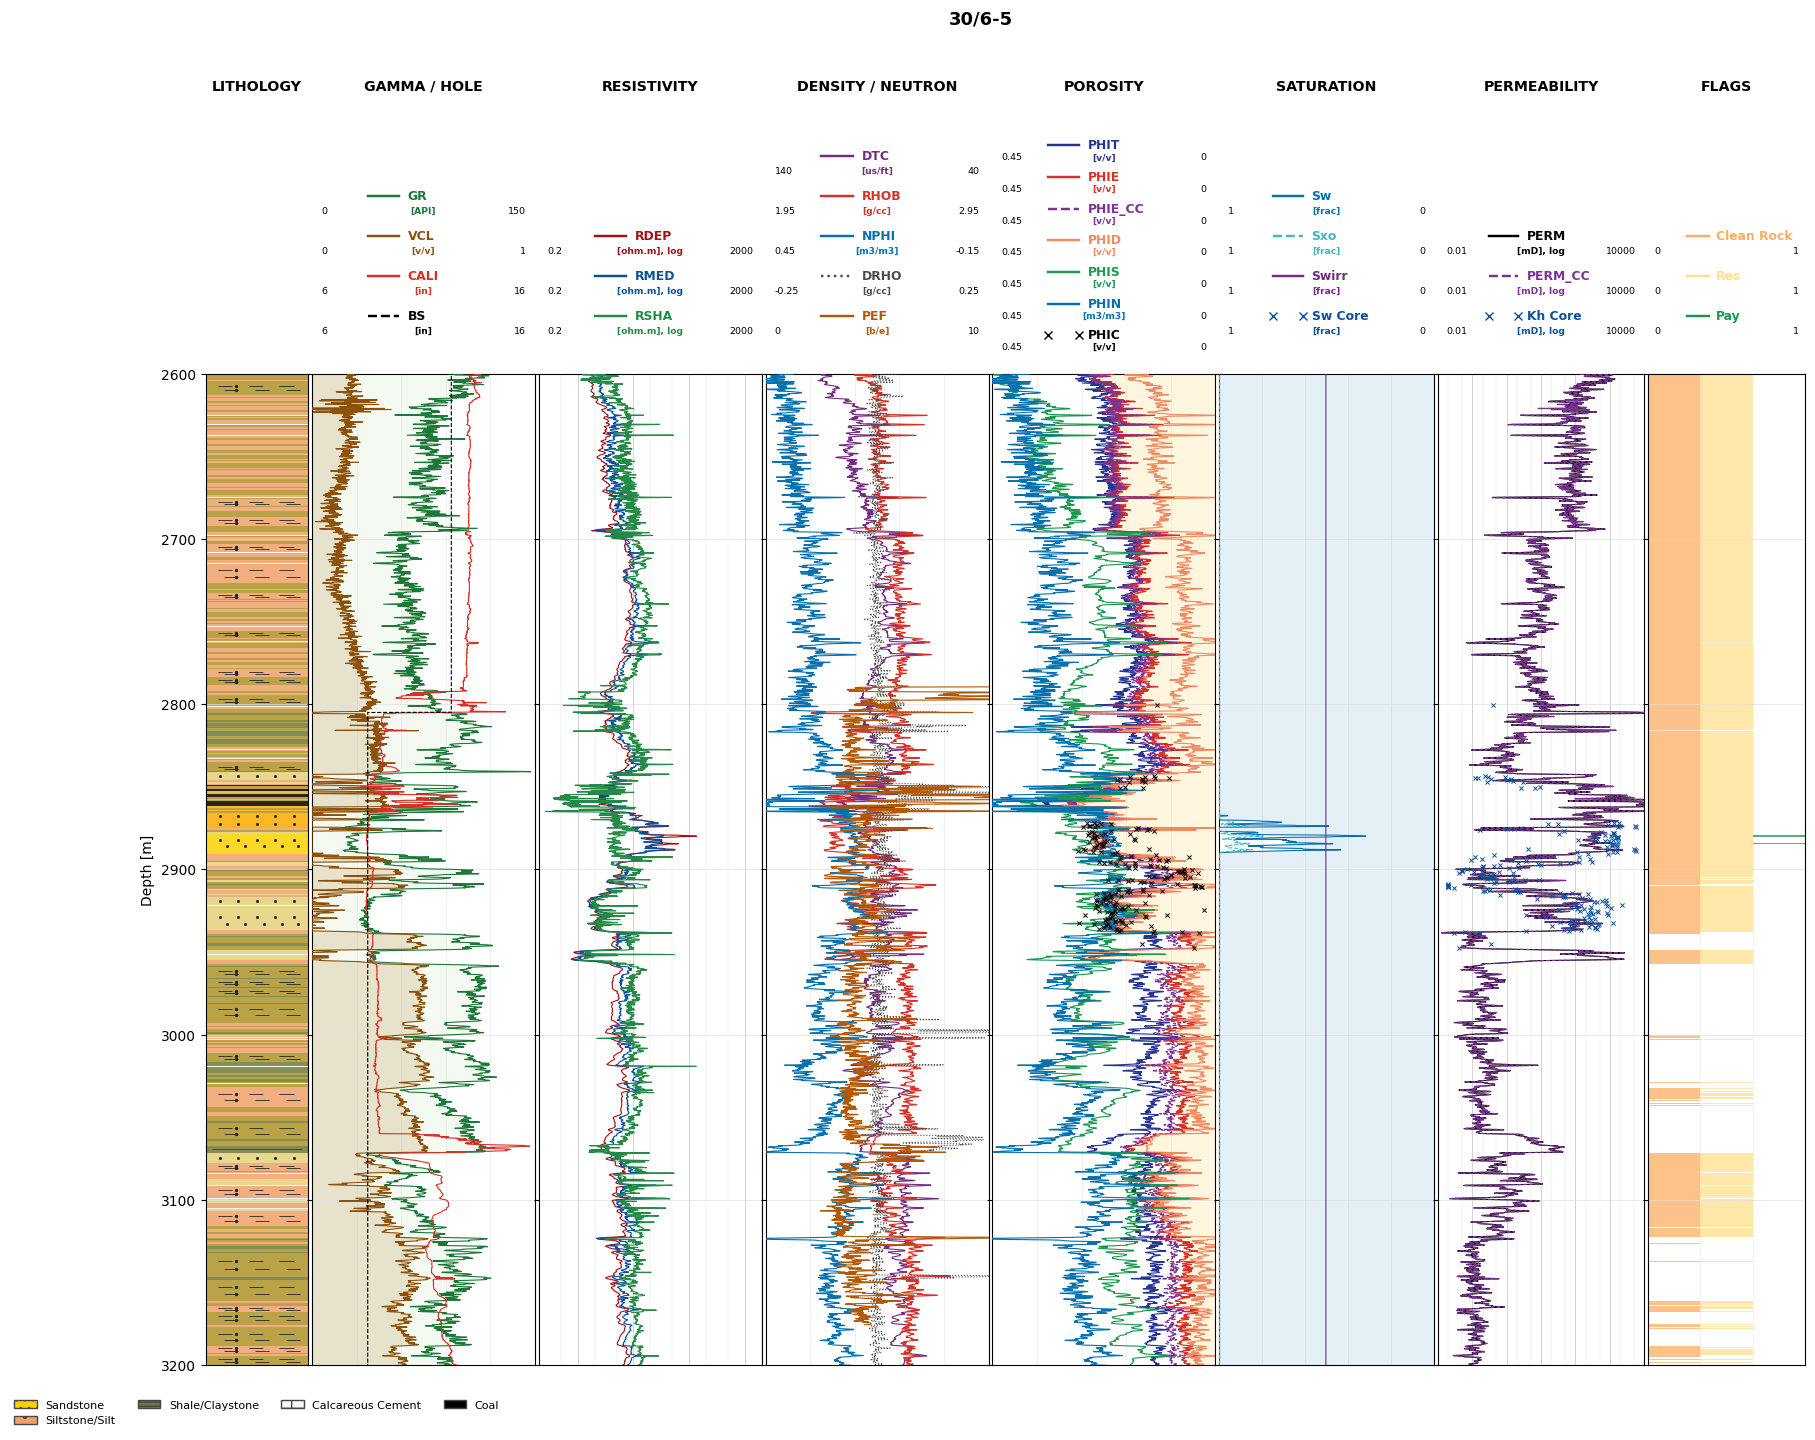

In [4]:
tmpl = create_adaptive_log_viewer_template(geo)
print("adaptive template tracks:")
for t in tmpl.tracks:
    curves = [c.curve_name for c in t.curves]
    print("  %-18s %s" % (t.display_name, curves))

viewer = create_log_viewer(geo, template_defaults="auto", depth_range=GEO_FULL)

The same `auto` template adapts to the carbonate well, which has fewer curves and no
vendor lithology log - note the different track set it produces.

HW-3 auto -> 9 tracks


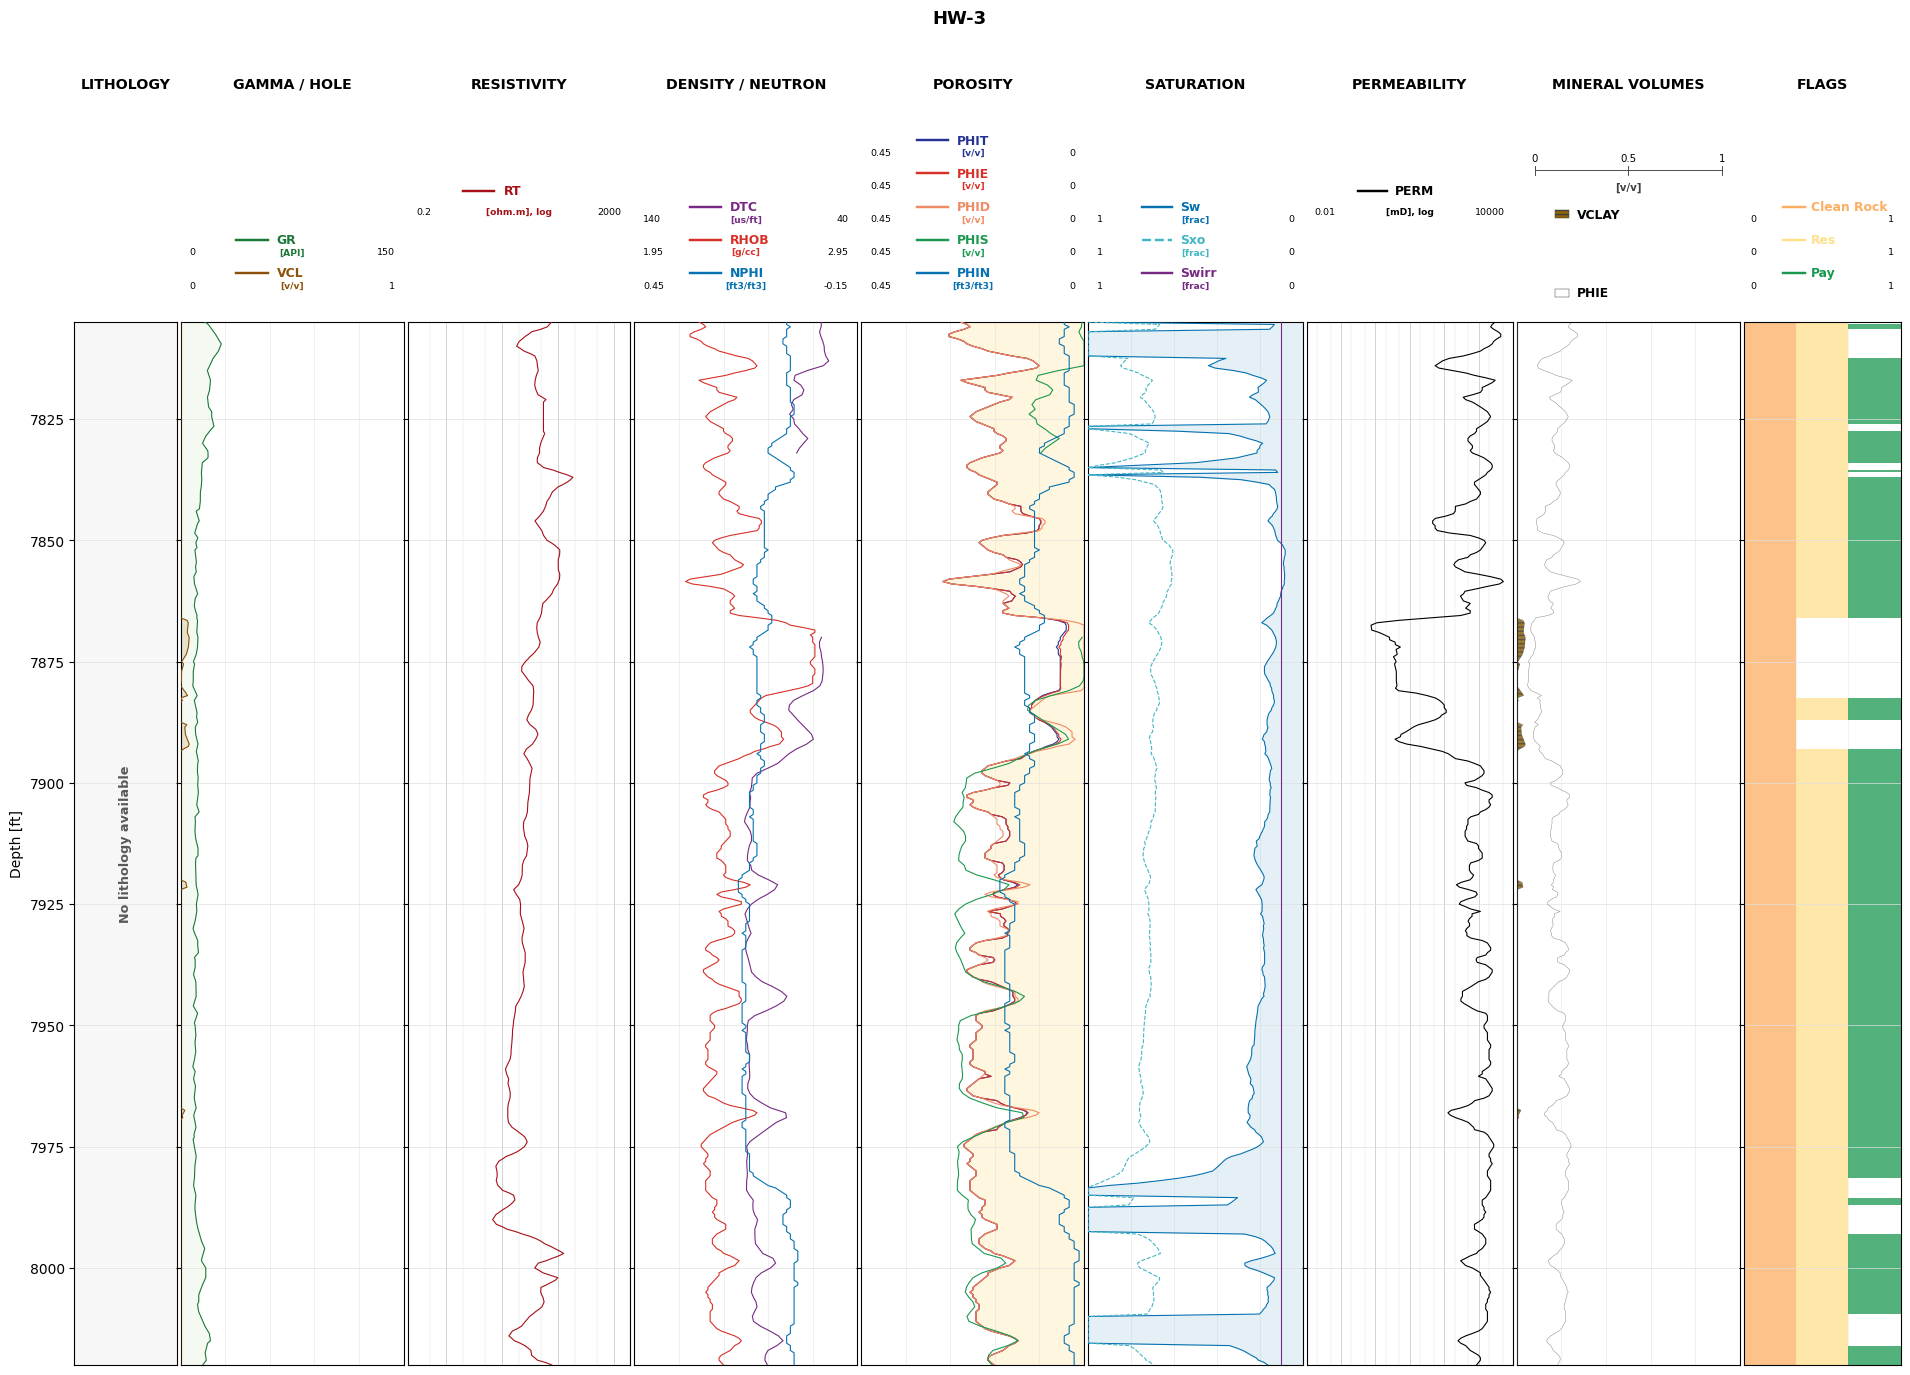

In [5]:
viewer = create_log_viewer(carb, template_defaults="auto")
print("HW-3 auto ->", len(viewer.axes), "tracks")

## 2. Triple combo

`create_triple_combo` is the classic quick-look, and "triple" means exactly
three measurement families in three tracks:

1. **Correlation** - GR (shaded), SP, and caliper against bit size. SP lives
   here, with GR, per industry convention.
2. **Resistivity** - deep / medium / shallow on a log scale.
3. **Porosity** - neutron and density on compatible scales (NPHI 0.45 to -0.15
   v/v against RHOB 1.95 to 2.95 g/cc), with the DRHO QC curve dotted.

It is the fastest way to eyeball reservoir vs seal and hydrocarbon crossover.
Sonic is deliberately not part of the display - adding it makes a quad combo,
which you can build with a custom template. One call, sensible defaults.

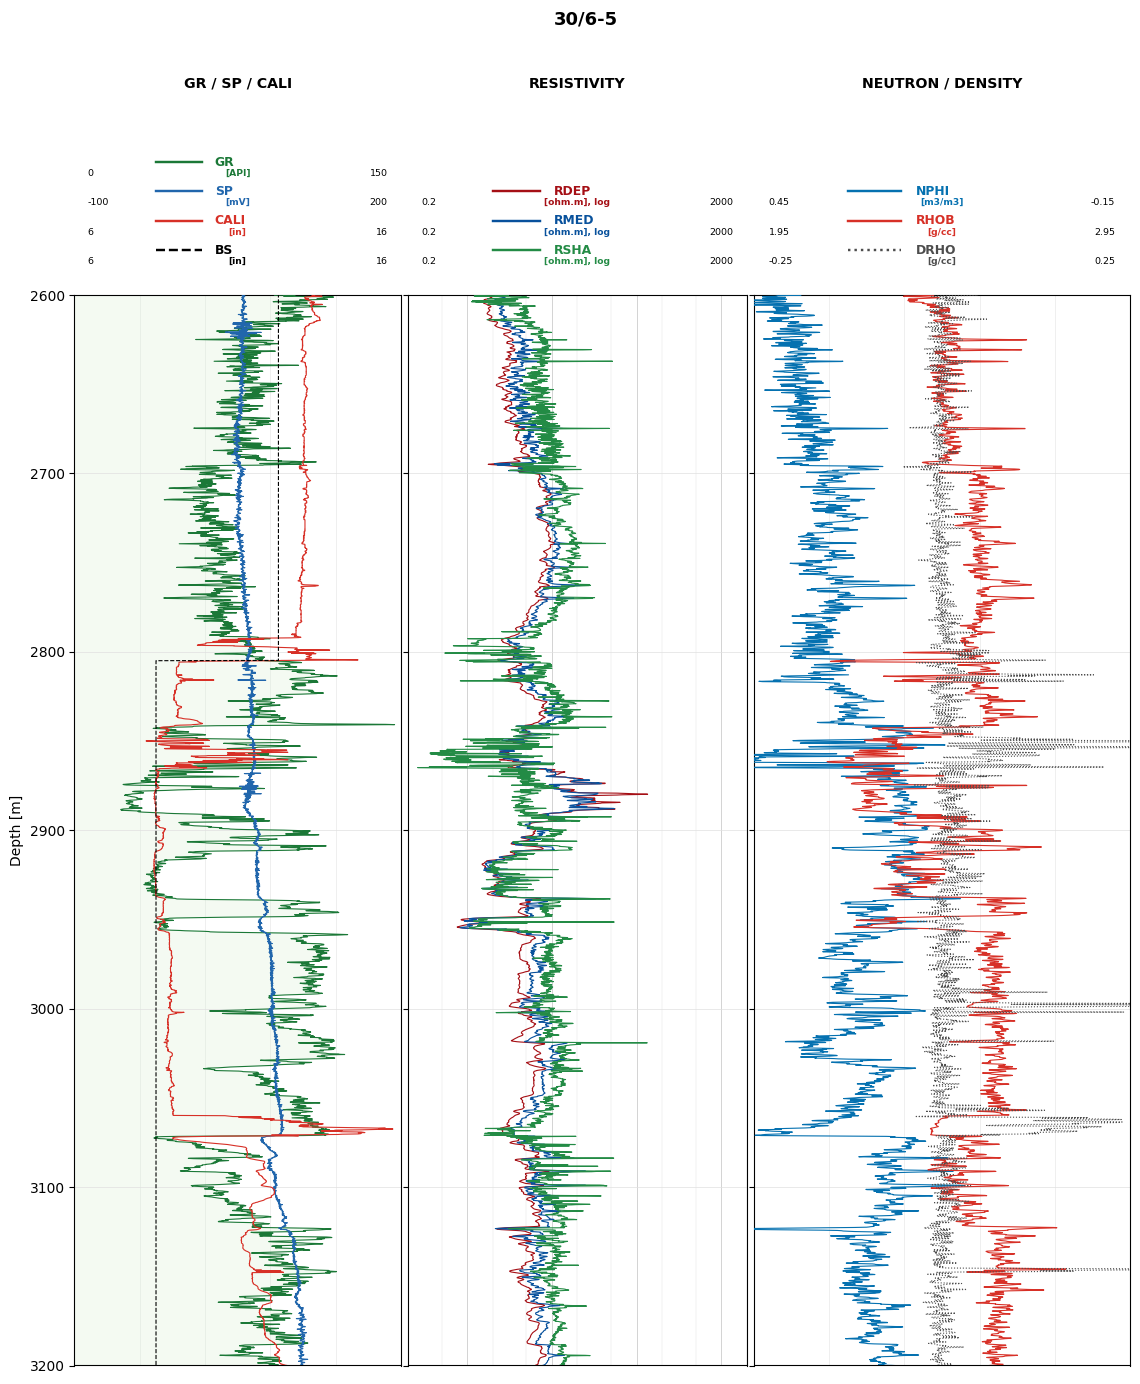

In [6]:
create_triple_combo(geo, depth_range=GEO_FULL)
plt.show()

## 3. The crossplot family

Crossplots move from depth-vs-value tracks to **value-vs-value** scatter, which is where
lithology, porosity model, and saturation logic become visible.

### 3a. Neutron-density crossplot

`create_nd_crossplot` plots NPHI against RHOB with lithology lines; points are coloured
by a third curve (default `GR`). Sandstone, limestone, and dolomite trends separate here,
and gas pulls points toward low apparent density / low neutron. We restrict to the PEF-live
interval where lithology work is valid on 30/6-5.

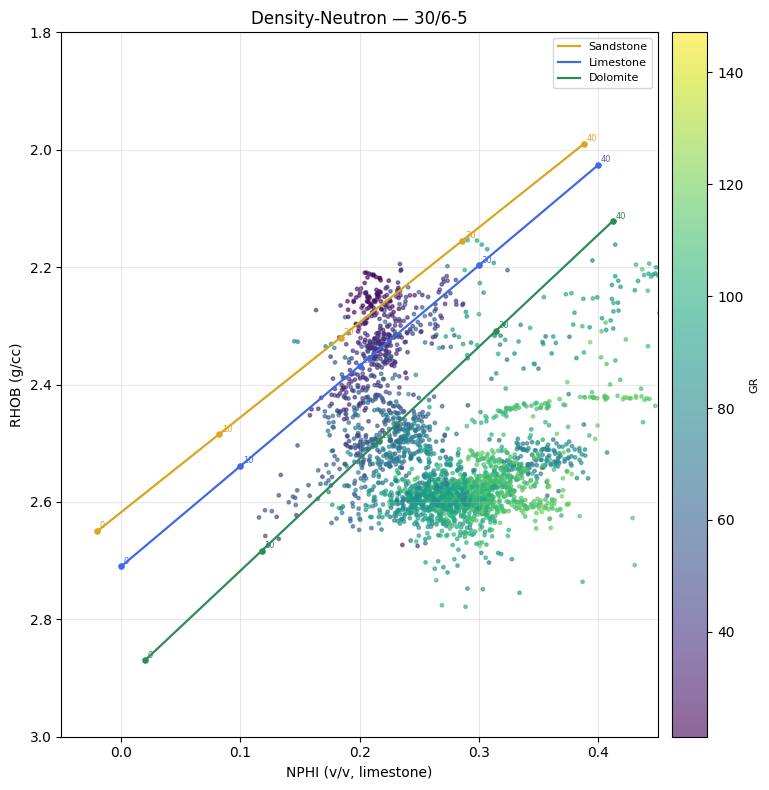

In [7]:
create_nd_crossplot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

### 3b. Pickett plot

`create_pickett_plot` plots `log(RT)` vs `log(PHIE)`. In a clean, water-bearing zone the
100%-water points scatter about a straight line whose slope is `-m` (its magnitude is the
cementation exponent) and whose intercept fixes `Rw`. Hydrocarbon points sit **above**
the water line. We run it on the Statfjord water sand (a hydrocarbon interval would give
too few water points).

The parameters are not free knobs: we use the operator's own evaluation constants
(a=0.80, m=n=2, Rw=0.070 ohm.m at reservoir temperature, from the Statoil completion
report validated in notebook 09). A quick self-check below confirms them: the median
apparent water resistivity of the clean points in this window, Rt x PHIE^2 / a, lands
within a few percent of 0.070 - so the Sw=100% line passes through the water cloud, as
it must on a wet interval. (Plotting the same window with a too-low guess like
Rw=0.030 strands the entire water sand at an apparent Sw of 60-80%: the classic
mis-parameterised Pickett from notebook 07.)

median apparent Rw (Rt x PHIE^2 / a) on 1238 clean points: 0.068 ohm.m
operator Rw at reservoir temperature               : 0.070 ohm.m


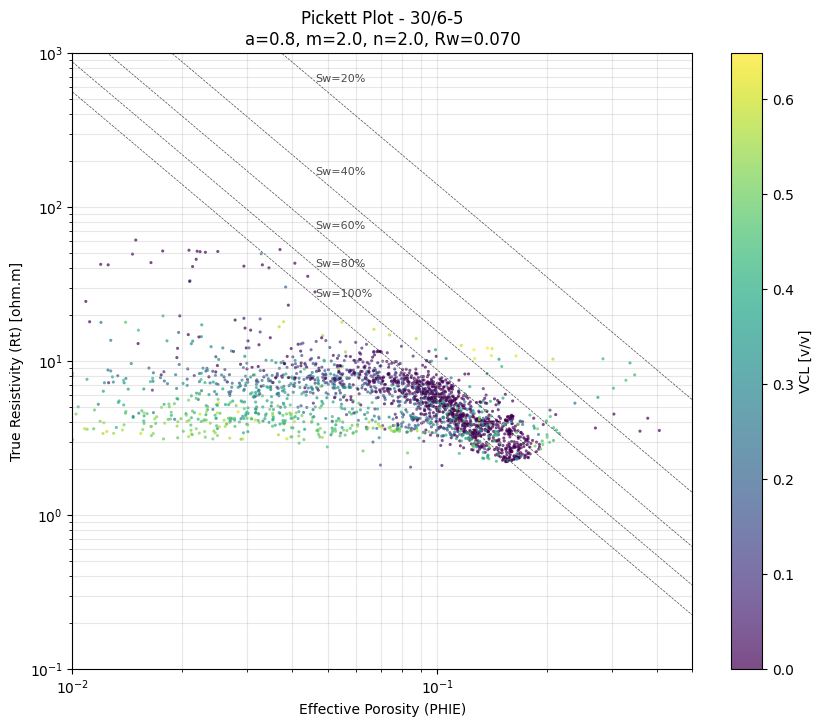

In [8]:
# Self-check: apparent Rw of the clean water-sand points at the operator's a, m.
d = np.asarray(geo.depth, float)
mwin = (d >= GEO_WATER[0]) & (d <= GEO_WATER[1])
phi_w = np.asarray(geo.get("PHIE").data, float)[mwin]
rt_w = np.asarray(geo.get("RDEP").data, float)[mwin]
vcl_w = np.asarray(geo.get("VCL").data, float)[mwin]
clean = np.isfinite(phi_w) & np.isfinite(rt_w) & np.isfinite(vcl_w) & (vcl_w < 0.3) & (phi_w > 0.05) & (rt_w > 0)
rw_app = float(np.nanmedian(rt_w[clean] * phi_w[clean] ** 2.0)) / 0.80
print("median apparent Rw (Rt x PHIE^2 / a) on %d clean points: %.3f ohm.m" % (clean.sum(), rw_app))
print("operator Rw at reservoir temperature               : 0.070 ohm.m")

create_pickett_plot(
    geo, rw=0.070, phie_curve="PHIE", rt_curve="RDEP",
    color_curve="VCL", depth_range=GEO_WATER, a=0.80, m=2.0, n=2.0,
)
plt.show()

### 3c. Hingle plot

`create_hingle_plot` is the Pickett plot's linear-grid cousin: it linearises the Archie
relation so the water line and `Rw` can be read on ordinary axes. Same water interval, same
operator parameters (a=0.80, m=n=2, Rw=0.070), different projection - useful when you
want to fit the water line by eye. Here the Sw=100% line bounds the top of the cloud
(highest conductivity at a given porosity = wettest rock), with the scatter fanning to
lower Sw lines.

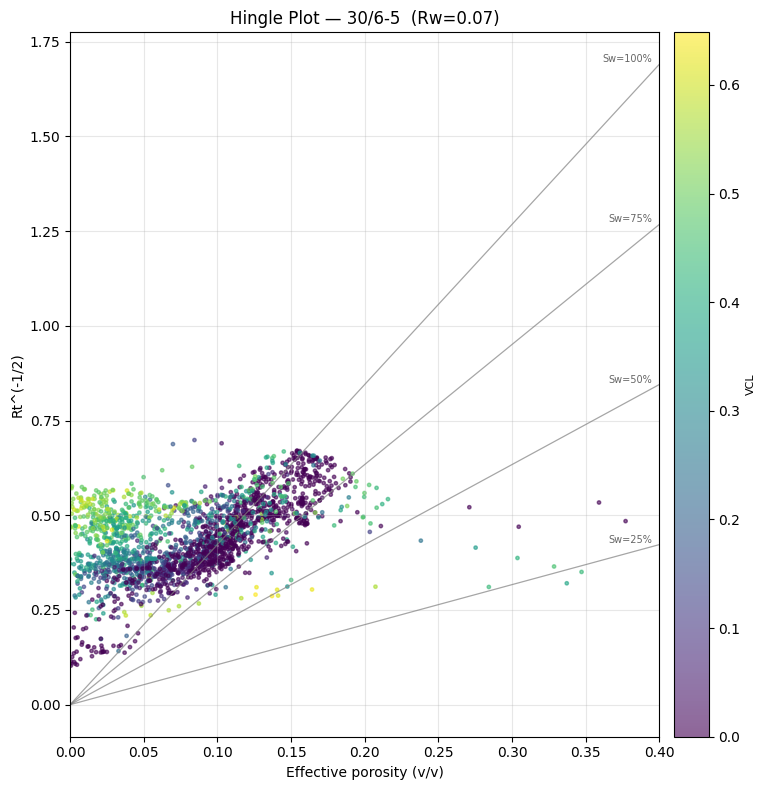

In [9]:
fig = create_hingle_plot(
    geo, rw=0.070, m=2.0, n=2.0, phie_curve="PHIE", rt_curve="RDEP",
    color_curve="VCL", a=0.80, depth_range=GEO_WATER,
)
# The library pins the iso-Sw labels at x=0.40 (the right axis limit), where they
# run off the frame; right-align them just inside it. Post-styling a returned
# figure like this works on any of the crossplot helpers.
ax = fig.axes[0]
for t in ax.texts:
    if t.get_text().startswith("Sw="):
        _, y = t.get_position()
        t.set_position((0.395, y))
        t.set_horizontalalignment("right")
        t.set_verticalalignment("bottom")
plt.show()

### 3d. M-N and MID lithology crossplots

`create_mn_plot` and `create_mid_plot` combine density, neutron, and sonic to identify
matrix mineralogy and flag secondary porosity / gas independent of a single crossplot.
Both need a sonic curve, which 30/6-5 has (`DTC`). Coloured by `GR`.

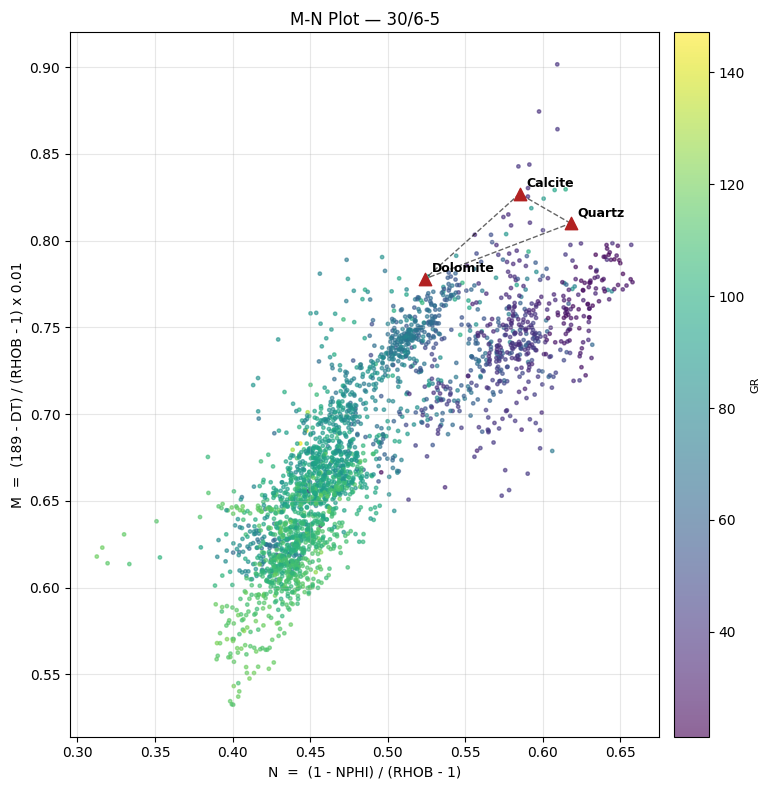

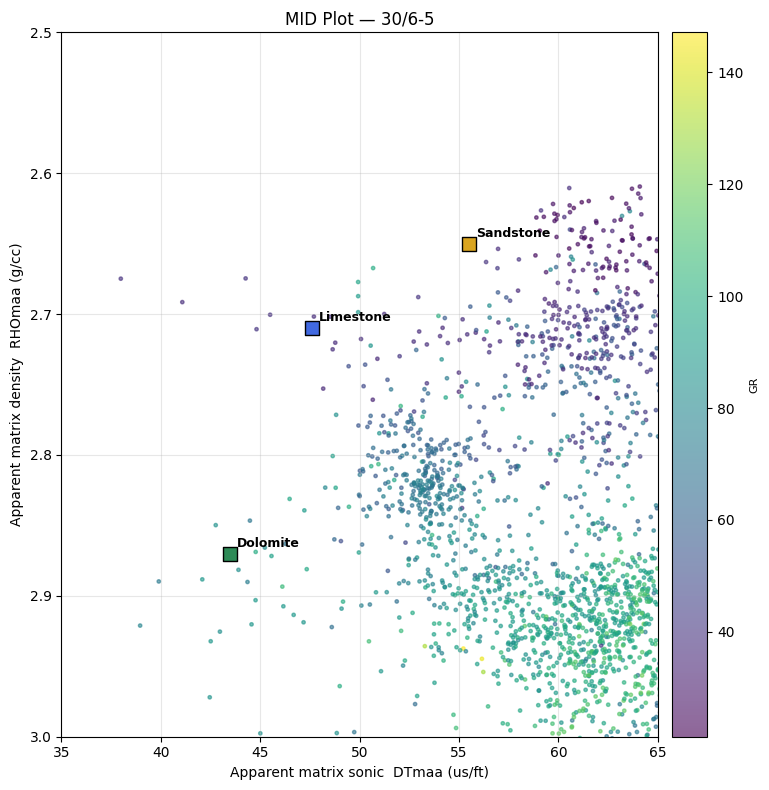

In [10]:
create_mn_plot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

create_mid_plot(geo, color_curve="GR", depth_range=GEO_LITH)
plt.show()

### 3e. Buckles plot

`create_buckles_plot` shows `PHIE` vs `SW`; points on a common `PHIE * SW = const`
hyperbola indicate a zone at **irreducible water** (constant bulk-volume water), which
predicts water-free production. Coloured by permeability. This is a carbonate reservoir
question, so we run it on HW-3.

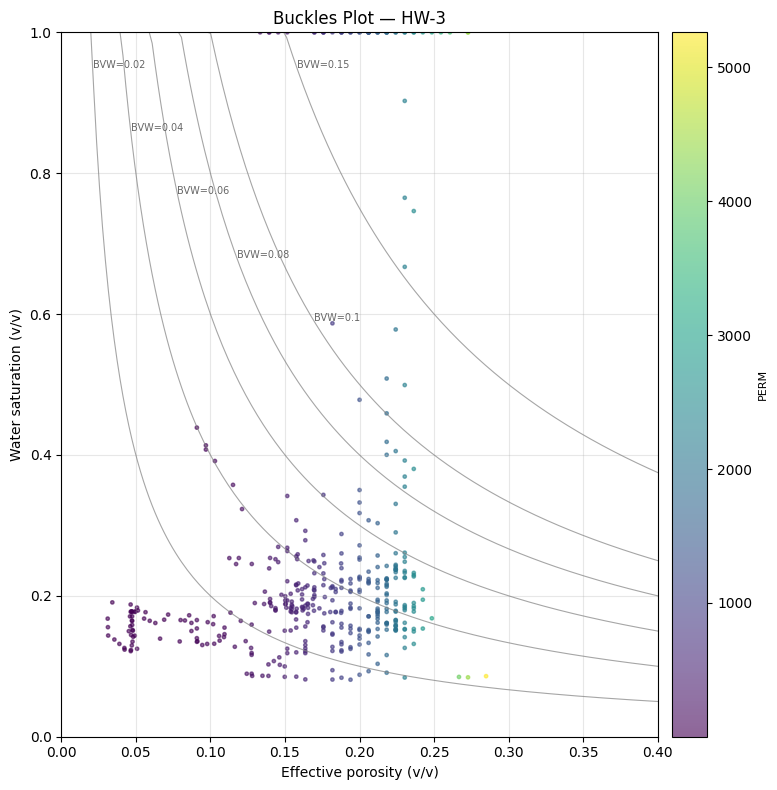

In [11]:
fig = create_buckles_plot(carb, phie_curve="PHIE", sw_curve="SW", color_curve="PERM")
# The library writes every BVW label at y=0.95, where the low-BVW hyperbolas
# converge and the labels overprint; restack each label along its own curve.
ladder = {"BVW=0.02": 0.95, "BVW=0.04": 0.86, "BVW=0.06": 0.77,
          "BVW=0.08": 0.68, "BVW=0.1": 0.59}
ax = fig.axes[0]
for t in ax.texts:
    y = ladder.get(t.get_text())
    if y is not None:
        bvw = float(t.get_text().split("=")[1])
        t.set_position((bvw / y, y))
plt.show()

## 4. Specialist panels

### 4a. Flow-unit (RQI vs phi_z) plot

`create_flow_unit_plot` renders a Reservoir Quality Index / flow-zone-indicator analysis.
Compute the units with `calculate_flow_units(perm_k, phi_e)` (note: **permeability
first**), then hand the result straight to the plot. The analysis only separates units
when permeability genuinely varies at fixed porosity, so we feed it **real core plugs**:
30/6-5 carries `PHIC` (core porosity) and `KH_CORE` (core horizontal permeability). A
log-derived `PERM` curve would be a poor input here - the standard workflow computes it
*from* porosity, so its FZI collapses onto a single trend by construction. On the
log-log RQI-vs-phi_z axes each unit clusters around its own constant-FZI line, so the
units stack as parallel diagonal bands.

core plugs with both PHIC and KH_CORE: 198
flow-unit result type: FlowUnitResult | units found: 6


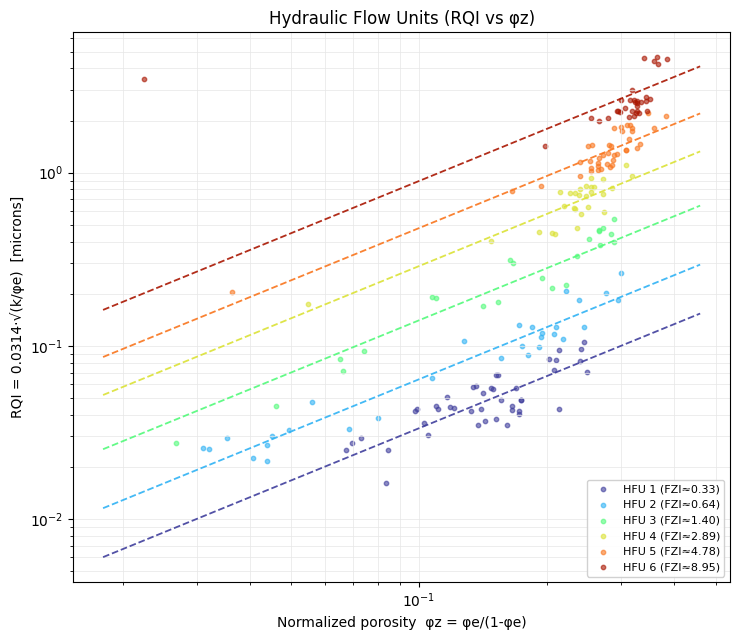

In [12]:
# Real core plugs on 30/6-5: PHIC = core porosity, KH_CORE = core horizontal perm.
phic = geo.get("PHIC").data
kh_core = geo.get("KH_CORE").data
plugs = np.isfinite(phic) & np.isfinite(kh_core)
print("core plugs with both PHIC and KH_CORE:", int(plugs.sum()))

fu = calculate_flow_units(kh_core[plugs], phic[plugs])   # perm_k first, then phi_e
print("flow-unit result type:", type(fu).__name__, "| units found:", fu.n_units)

create_flow_unit_plot(result=fu)
plt.show()

### 4b. NMR panel - real CMR (Daydream 1)

`create_nmr_panel` builds the standard CMR display: GR/QC, borehole calipers,
CMR porosity split into bound and free fluid, NMR permeability, and Swirr with
the T2 cutoff. It needs NMR summary curves such as `TCMR`, `CMFF`, `KTIM`;
`has_nmr_curves(well)` tells you whether a well qualifies.

Neither teaching well carries NMR, but the package bundles the **real
Daydream 1 CMR log** (notebook 14 works it end to end), and its curves are
exactly what the panel wants. The window below covers the coal streaks around
3900-4100 m.

has_nmr_curves -> True


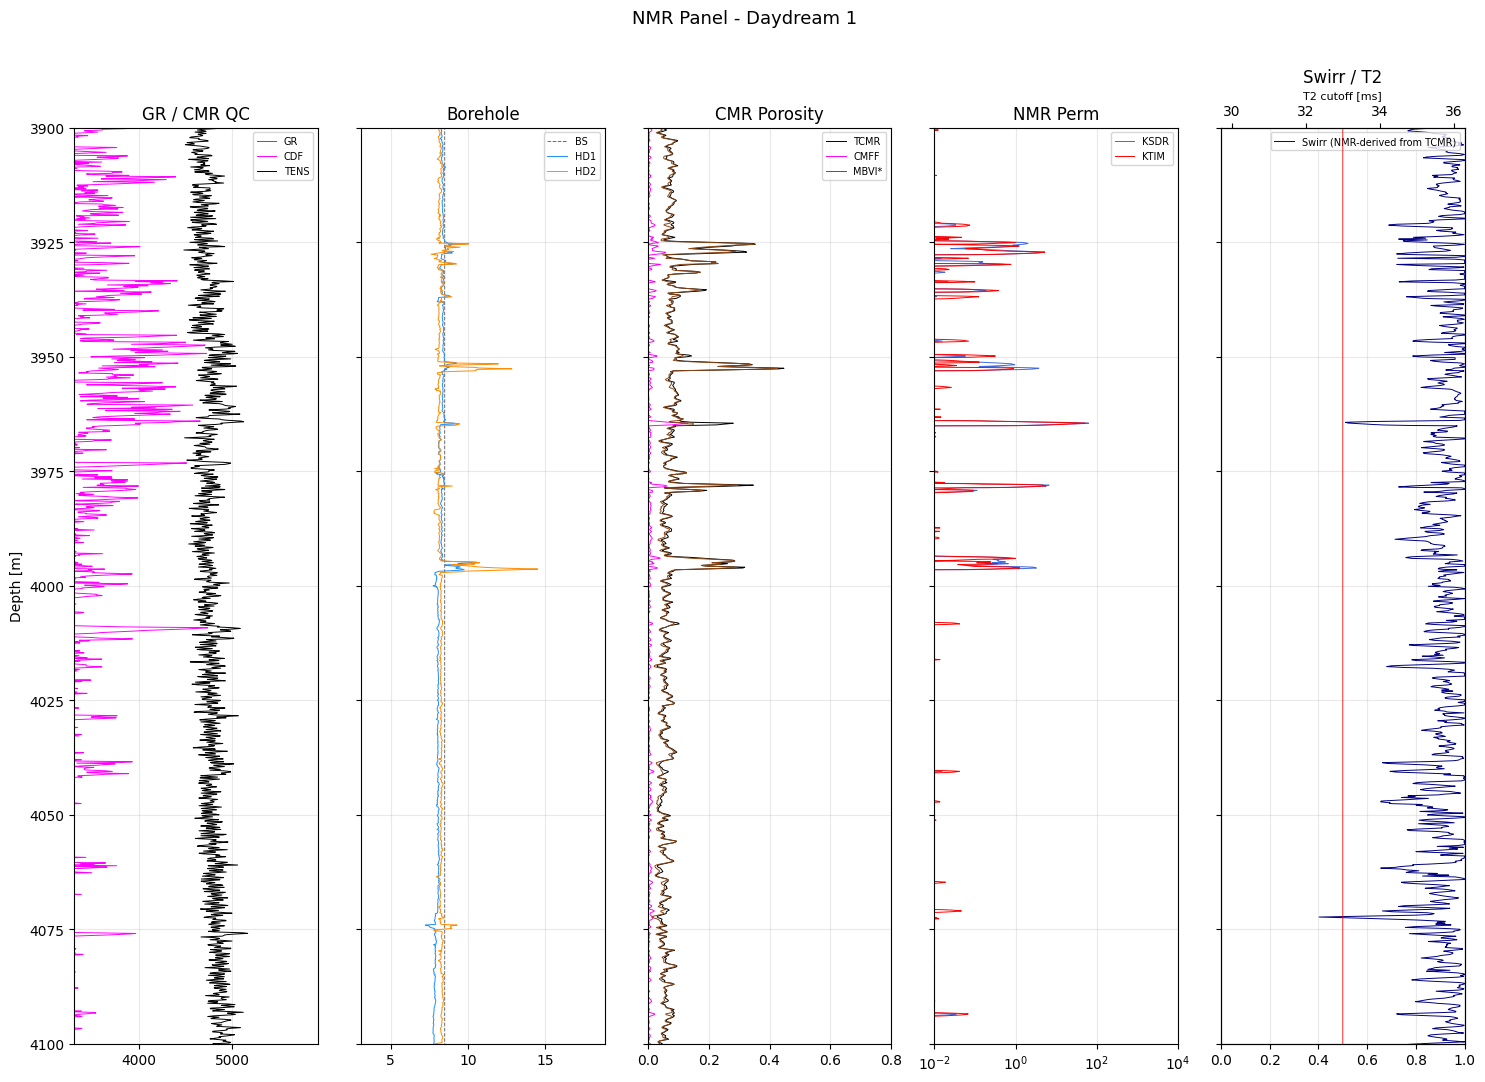

In [13]:
nmr_well = read_las(petrophys.sample("daydream1_cmr"))
print("has_nmr_curves ->", has_nmr_curves(nmr_well))

create_nmr_panel(nmr_well, depth_range=(3900.0, 4100.0))
plt.show()

### 4c. FMI panel - rendered in notebook 16

`create_fmi_panel` takes a `BoreholeImageData` (a pad/button resistivity image
plus a navigation curve), orients it to azimuth, equalizes, and renders the
standard image display. The large Daydream image DLIS is held in Git LFS rather
than the Python wheel, so the panel is not rendered here; after `git lfs pull`,
notebook 16 discovers it automatically. `PETROPHYS_FMI_DLIS` remains an override.

## 5. Zone flags and formation shading

`plot_zone_flags` renders discrete flag curves (net rock / reservoir / pay) as coloured
bars against depth - an at-a-glance summary of where the pay is. It returns
`(fig, axes)`.

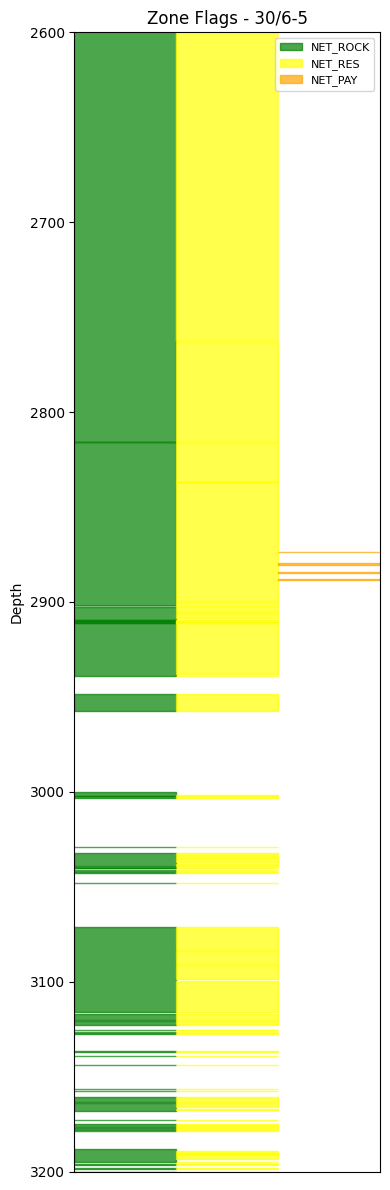

In [14]:
fig, ax = plot_zone_flags(
    geo, flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"], depth_range=GEO_FULL,
)
plt.show()

`add_zone_shading` decorates an existing axis with translucent depth bands - handy for
highlighting named intervals on any custom track. Each zone is a dict with `top` and
`bottom` plus optional `name` and `color` keys; the zone `name` is drawn on the band
and used in the legend.

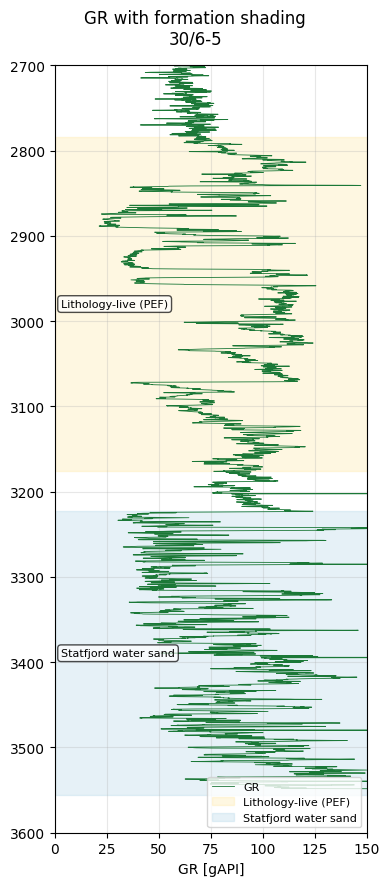

In [15]:
from petrophys.visualization import LogPlot

# Render GR with the library LogPlot, then decorate its axis with formation
# shading. add_zone_shading operates on any matplotlib axis, including the one
# LogPlot creates.
lp = LogPlot(geo, figsize=(4, 9))
lp.create_figure(n_tracks=1)
lp.add_curve(0, "GR", color="#1b7837", linewidth=0.6, xlim=(0, 150))
lp.set_depth_range(top=2700.0, bottom=3600.0)   # wide enough to hold both zones
lp.add_title("GR with formation shading")

zones = [
    {"top": 2784.0, "bottom": 3176.0, "color": "#fee08b", "name": "Lithology-live (PEF)"},
    {"top": 3223.0, "bottom": 3556.0, "color": "#9ecae1", "name": "Statfjord water sand"},
]
add_zone_shading(lp.axes[0], zones, alpha=0.25)
lp.axes[0].legend(loc="lower right", fontsize=8)
lp.show()

## 6. Non-log analytics helpers

Beyond depth-track logs and crossplots, `petrophys.visualization` ships a small
set of **general analytics charts** for multi-well studies, model comparisons
and sensitivity work. They take plain arrays (or `Well` objects) so you never
hand-roll matplotlib:

- `create_multiwell_overlay` - one curve versus depth across several wells;
- `create_bar_comparison` - single or grouped ranking bars;
- `create_tornado_plot` - a sensitivity tornado about a base case;
- `create_histogram_comparison` - overlaid distributions;
- `create_line_comparison` - generic x versus many y-series lines.

We demonstrate each on real Geolink wells.

### 6a. Multi-well curve overlay

`create_multiwell_overlay(wells, curve, ...)` overlays one curve versus depth for
several wells on a shared axis - the standard cross-well QC view. With
`normalize=True` each curve is robustly min-max scaled to 0-1 so their shapes
compare directly regardless of absolute GR level.

wells with GR: ['30/6-5', '16/7-1', '25/5-1 Froey', '15/9-14']


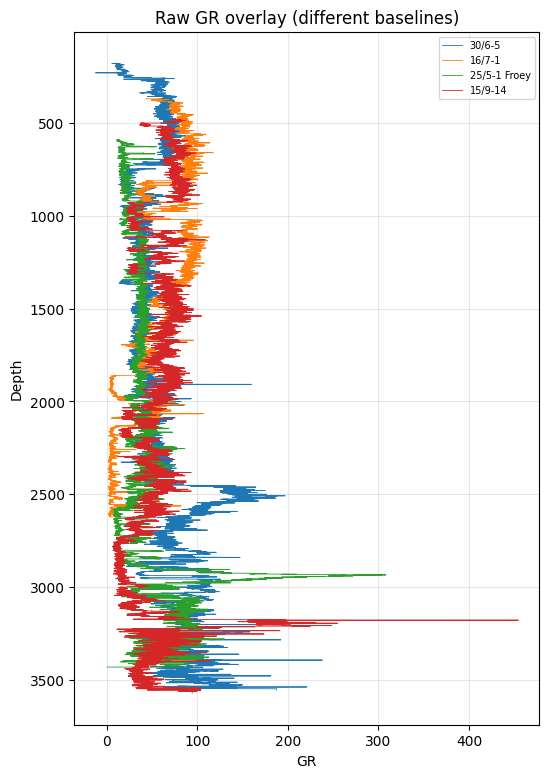

In [16]:
from petrophys.visualization import (
    create_multiwell_overlay, create_bar_comparison, create_tornado_plot,
    create_histogram_comparison, create_line_comparison,
)

# Load a few Geolink wells (all in metres) that carry GR.
field_names = ["30_6-5", "16_7-1", "25_5-1", "15_9-14"]
field_wells = [read_las(petrophys.sample(n)) for n in field_names]
field_wells = [w for w in field_wells if w.has_curve("GR")]
print("wells with GR:", [w.name for w in field_wells])

fig, ax = create_multiwell_overlay(
    field_wells, "GR", normalize=False,
    title="Raw GR overlay (different baselines)", figsize=(6, 9),
)
plt.show()

### 6b. Grouped/ranking bar comparison

`create_bar_comparison(categories, values, ...)` draws single or grouped bars.
`values` may be a 1-D sequence or a `{series: values}` mapping for grouped bars;
`sort_by` ranks the categories by a chosen series. Here we rank wells by their
mean GR and, as a second series, their GR standard deviation.

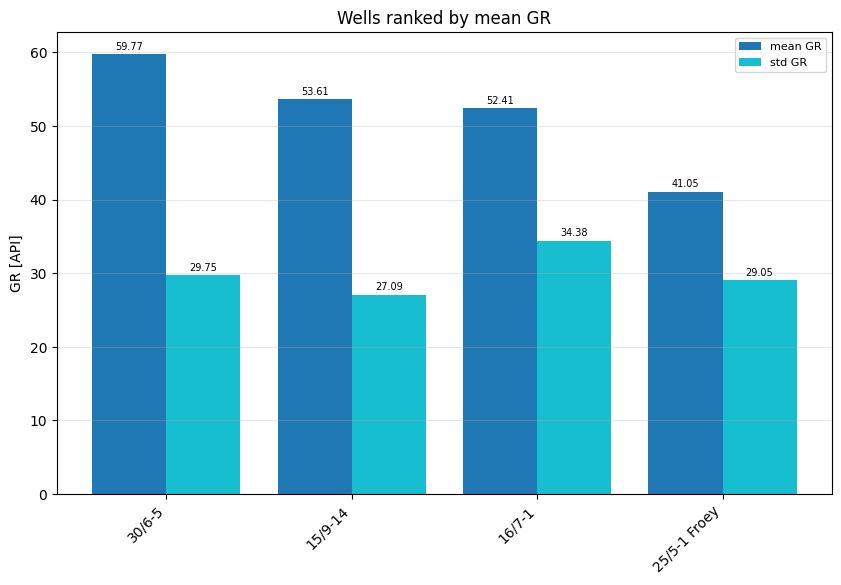

In [17]:
cats = [w.name for w in field_wells]
mean_gr = [float(np.nanmean(w.get("GR").data)) for w in field_wells]
std_gr = [float(np.nanstd(w.get("GR").data)) for w in field_wells]

fig, ax = create_bar_comparison(
    cats, {"mean GR": mean_gr, "std GR": std_gr},
    sort_by=0, descending=True, value_labels=True,
    ylabel="GR [API]", title="Wells ranked by mean GR",
)
plt.show()

### 6c. Sensitivity tornado

`create_tornado_plot(labels, low, high, base, ...)` shows how an outcome swings
when each input takes its low/high setting, sorted widest-span-on-top. Below we
sweep an Archie water-saturation calculation (single representative point) over
+/- ranges of `Rw`, `m`, `n` and `PHIE`, and plot the resulting Sw span.

base Sw = 0.265


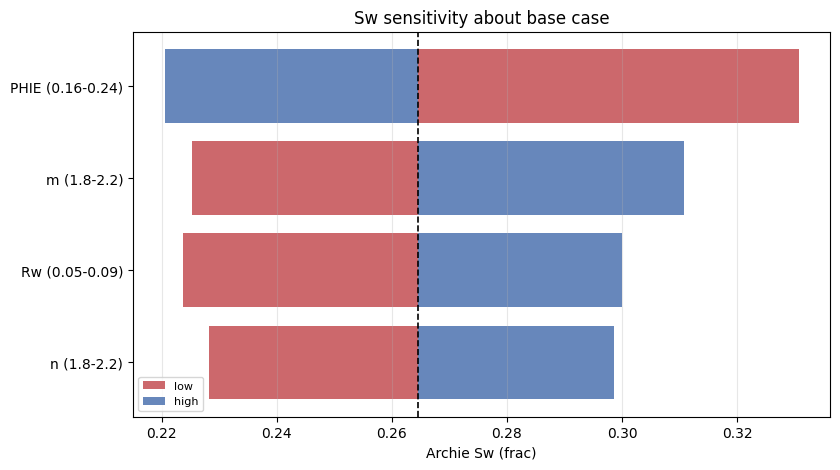

In [18]:
from petrophys.interpretation.saturation import archie

# Representative reservoir point on 30/6-5.
base = dict(rt=20.0, phie=0.20, rw=0.070, a=0.80, m=2.0, n=2.0)   # operator constants (notebook 09)
def sw(**kw):
    p = dict(base); p.update(kw)
    return float(archie(rt=p["rt"], rw=p["rw"], phi=p["phie"],
                        a=p["a"], m=p["m"], n=p["n"]))

sw_base = sw()
params = {
    "Rw (0.05-0.09)":  (sw(rw=0.05), sw(rw=0.09)),
    "m (1.8-2.2)":     (sw(m=1.8),   sw(m=2.2)),
    "n (1.8-2.2)":     (sw(n=1.8),   sw(n=2.2)),
    "PHIE (0.16-0.24)":(sw(phie=0.16), sw(phie=0.24)),
}
labels = list(params)
low = [params[k][0] for k in labels]
high = [params[k][1] for k in labels]
print("base Sw = %.3f" % sw_base)

fig, ax = create_tornado_plot(
    labels, low, high, base=sw_base,
    xlabel="Archie Sw (frac)", title="Sw sensitivity about base case",
)
plt.show()

### 6d. Histogram comparison

`create_histogram_comparison({label: array, ...})` overlays distributions on a
common bin grid. A classic use is comparing a curve's spread across wells (or
before/after normalization); here we compare each well's GR distribution.

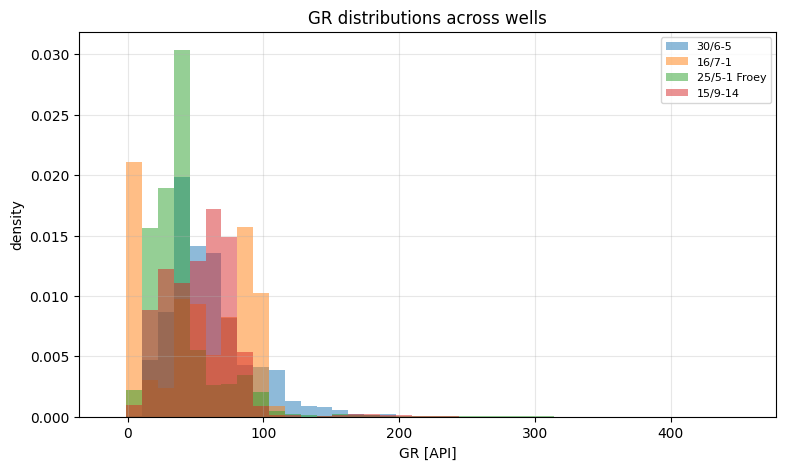

In [19]:
gr_dists = {w.name: w.get("GR").data for w in field_wells}
fig, ax = create_histogram_comparison(
    gr_dists, bins=40, density=True,
    xlabel="GR [API]", title="GR distributions across wells",
)
plt.show()

### 6e. Line comparison (transfer functions)

`create_line_comparison(x, {label: y, ...})` is the generic x-versus-many-series
plotter for things that are not depth tracks: transfer functions, temperature
profiles, and similar. Here we compare the common **Vcl-from-GR transfer
functions** (linear vs the two Larionov forms and Clavier) over the full IGR
range.

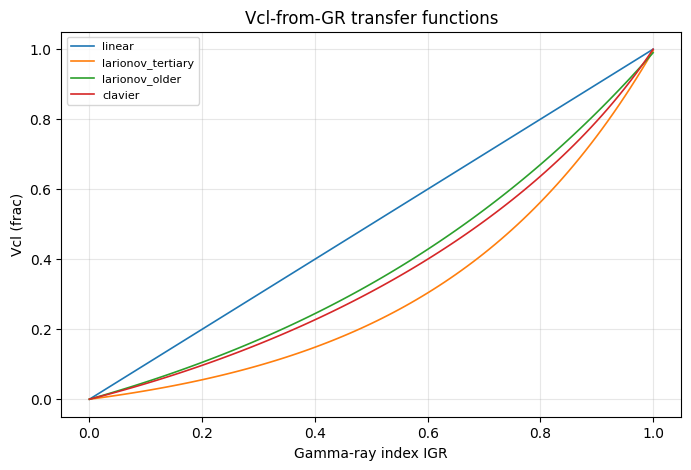

In [20]:
from petrophys.interpretation.clay_volume import vcl_from_gr

igr = np.linspace(0.0, 1.0, 101)     # gamma-ray index (0 clean -> 1 shale)
gr = igr * 100.0                     # map onto a 0-100 API scale (gr_min=0, gr_max=100)
transfer = {
    "linear":            vcl_from_gr(gr, 0.0, 100.0, method="linear"),
    "larionov_tertiary": vcl_from_gr(gr, 0.0, 100.0, method="larionov_tertiary"),
    "larionov_older":    vcl_from_gr(gr, 0.0, 100.0, method="larionov_older"),
    "clavier":           vcl_from_gr(gr, 0.0, 100.0, method="clavier"),
}
fig, ax = create_line_comparison(
    igr, transfer,
    xlabel="Gamma-ray index IGR", ylabel="Vcl (frac)",
    title="Vcl-from-GR transfer functions",
)
plt.show()

## Pitfalls & parameter choices

- **`create_log_viewer` renders immediately.** The factory builds the figure before it
  returns, so the `LogViewer` already holds `viewer.fig` / `viewer.axes` windowed to the
  `depth_range` you passed. Calling `.create()` again re-renders from scratch and
  **drops the depth window** unless you pass it again - a silent way to lose your zoom.
  Display the eagerly-built figure once; use `.close()` to free memory in loops.
- **`auto` template is curve-driven.** It silently drops tracks whose curves are absent -
  great for robustness, but check `create_adaptive_log_viewer_template(well)` if a track
  you expected is missing.
- **Pickett/Hingle need water points.** Run them on a **water-bearing** interval; a pure
  hydrocarbon zone has too few 100%-water points and the water-line fit degrades.
- **`calculate_flow_units(perm_k, phi_e)` takes permeability first.** Swapping the
  arguments silently produces nonsense bands. Feed it data where permeability truly
  varies at fixed porosity (core plugs such as `PHIC`/`KH_CORE`); a porosity-derived
  log `PERM` collapses FZI onto one trend.
- **Lithology crossplots need the right curves live.** On 30/6-5, `PEF` and lithology work
  are only valid in ~2784-3176 m; outside that the points are unconstrained.
- **NMR / FMI panels need the right inputs** (`has_nmr_curves`, a navigation curve).
  The NMR panel renders here from the bundled real Daydream 1 CMR; the FMI panel
  needs an image DLIS - notebook 16 runs it on the real Daydream 1 image.

## Recap

- The **template log viewer** (named or `auto`) is your general-purpose multi-track
  display; the **triple combo** is the fast first look.
- The **crossplot family** each answers a specific question: N-D for lithology/gas,
  Pickett/Hingle for `Rw`/`m` and the water line, M-N/MID for matrix mineralogy, Buckles
  for irreducible-water/producibility.
- **Specialist panels** cover flow units (real 30/6-5 core plugs) and the NMR
  display (real Daydream 1 CMR); the FMI panel renders in notebook 16.
- **Zone flags** and **formation shading** annotate results directly on depth.

## Try it yourself

> **Exercise 1.** Render `create_log_viewer(geo, template_defaults="petrophysics")` and
> compare its track layout with `geolink_full`. Which curves each template emphasises tells
> you its intended audience.
>
> **Exercise 2.** Re-run the Pickett plot with `m=1.8` and `m=2.2`. How does the assumed
> cementation exponent move the water line, and hence computed `Sw`?
>
> **Exercise 3.** Build a Buckles plot on the clastic well `geo` over `GEO_FULL`. Do the
> points hug a single `PHIE*SW` hyperbola (irreducible) or scatter (transition zone)?

## What's next

Continue with **18_multiwell_field_study.ipynb**, where these single-well plots scale up:
we batch-process the 17-well Costa field, normalise logs across wells, and build a
cross-well comparison table and summary figure.